In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [2]:
## lens orangje
V_O = [0.0006, 0.101, 0.196, 0.296, 0.348, 0.397, 0.498, 0.600, 1.001 ] # in volt
I_O = [2.02,   1.73,  1.35,  0.90,  0.64,  0.45,  0.20,  0.15,  0.10  ] # in nA
dV_O = [0.0001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001 ]
dI_O = [0.10,   0.05,  0.05,  0.05,  0.05,  0.05,  0.05,  0.10,  0.10]

In [3]:
## lens groen
V_G = [0.0006, 0.097, 0.204, 0.296, 0.396, 0.498, 0.601, 0.699]
I_G = [1.40,   1.15,  1.00,  0.70,  0.45,  0.30,  0.15,  0.07]
dV_G = [0.0001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]
dI_G = [0.05,   0.05,  0.05,  0.10,  0.10,  0.10,  0.10,  0.05]

In [4]:
## Lens blauw
V_B = [0.0006, 0.096, 0.198]
I_B = [0.20,   0.12,  0.07]
dV_B= [0.0001, 0.001, 0.001]
dI_B = [0.10,   0.20,  0.20]

In [5]:
## lens zilver + paars
V_ZP = [0.0006, 0.103, 0.204]
I_ZP = [0.40,   0.30,  0.26]
dV_ZP = [0.0001, 0.001, 0.001]
dI_ZP = [0.10,   0.10,  0.10]

In [6]:
 ## orangje op nul
V_O = [0.0006, 0.101, 0.196, 0.296, 0.348, 0.397, 0.498, 0.600,] # in volt
I_O = [2.02,   1.73,  1.35,  0.90,  0.64,  0.45,  0.20,  0.15] # in nA
dV_O = [0.0001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]
dI_O = [0.10,   0.05,  0.05,  0.05,  0.05,  0.05,  0.05,  0.10]

In [7]:
## orangje op 3cm
V_O3 = [0.0006, 0.108, 0.198, 0.296, 0.397, 0.497, 0.606, 0.708, 0.795]
I_O3 =[1.00,   0.80,  0.70,  0.50,  0.40,  0.25,  0.18,  0.13,  0.05]
dV_O3 = [0.0001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]
dI_O3= [0.10,   0.10,  0.10,  0.10,  0.10,  0.10,  0.10,  0.10,  0.10]

In [8]:
## orangje op 6cm
V_O6 = [0.0006, 0.100, 0.208, 0.296, 0.396, 0.496, 0.619 ]
I_O6 =  [1.00,   1.00,  0.73,  0.47,  0.30,  0.23,  0.12]
dV_O6 = [0.0001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]
dI_O6 = [0.10,   0.10,  0.10,  0.10,  0.10,  0.10,  0.10]  

In [9]:
 ## orangje op 9cm
V_O9 = [0.0006, 0.097, 0.197, 0.296, 0.395, 0.493, 0.597]
I_O9 = [0.70,   0.50,  0.42,  0.27,  0.26,  0.18,  0.15]
dV_O9 = [0.0001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001]
dI_O9 = [0.10,   0.10,  0.10,  0.10,  0.10,  0.10,  0.10]

In [10]:
# fit 

def find_U0(V, I, dI):
    V, I, dI = np.array(V), np.array(I), np.array(dI)
    mask = I > 0
    Vf, If, wf = V[mask], I[mask], 1.0 / dI[mask]
 
    # gewogen polyfit graad 1: [a, b]  met I = a*V + b
    coeffs, cov = np.polyfit(Vf, If, 1, w=wf, cov=True)
    a, b = coeffs
    sa, sb = np.sqrt(cov[0, 0]), np.sqrt(cov[1, 1])
 
    U0 = -b / a
    # foutpropagatie: σ_U0 = |U0| * sqrt((σ_a/a)² + (σ_b/b)²)
    if b != 0:
        sU0 = abs(U0) * np.sqrt((sa / a)**2 + (sb / b)**2)
    else:
        sU0 = np.nan
 
    return a, b, U0, sU0


In [11]:
datasets_1A = [
    (V_O,  I_O,  dV_O,  dI_O,  "Oranje",        "orange"),
    (V_G,  I_G,  dV_G,  dI_G,  "Groen",          "mediumseagreen"),
    (V_B,  I_B,  dV_B,  dI_B,  "Blauw",          "steelblue"),
    (V_ZP, I_ZP, dV_ZP, dI_ZP, "Zilver paarsachtig", "mediumpurple"),
]

  Oranje              U₀ = (0.545 ± 0.045) V
  Groen               U₀ = (0.707 ± 0.039) V
  Blauw               U₀ = (0.291 ± 0.037) V
  Zilver paarsachtig  U₀ = (0.567 ± 0.142) V


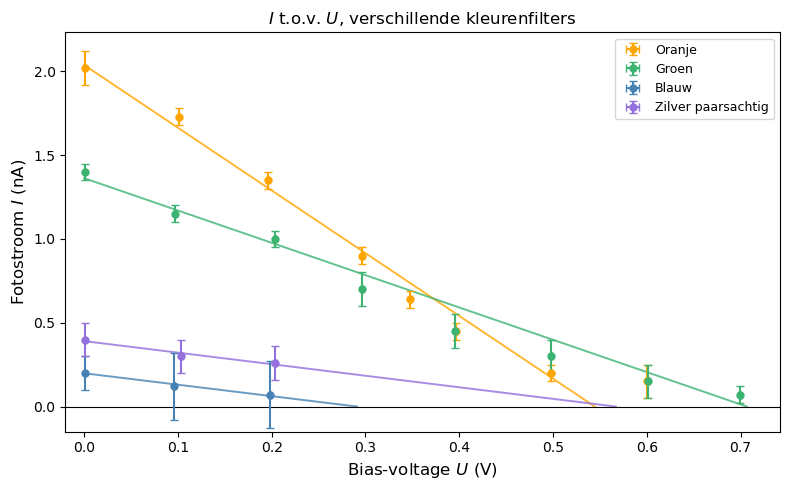

In [12]:
Lijst_U0_1 =[]
Lijst_fout_UO_1=[]

fig1, ax1 = plt.subplots(figsize=(8, 5)) 
for V, I, dV, dI, label, color in datasets_1A:
    V, I, dV, dI = np.array(V), np.array(I), np.array(dV), np.array(dI)
    ax1.errorbar(V, I, xerr=dV, yerr=dI,
                 fmt='o', color=color, markersize=5, capsize=3,
                 label=label, zorder=3)
    ## plot de fit
    a, b, U0, sU0 = find_U0(V, I, dI)
    Lijst_U0_1.append(U0)
    Lijst_fout_UO_1.append(sU0)
    
    if not np.isnan(U0):
        # fitlijn tekenen van V=0 tot V=U0
        V_fit = np.linspace(0, U0, 100)
        ax1.plot(V_fit, a * V_fit + b, color=color, linewidth=1.4,
                 linestyle='-', alpha=0.8)
        print(f"  {label:<18s}  U₀ = ({U0:.3f} ± {sU0:.3f}) V")
        
ax1.axhline(0, color='black', linewidth=0.8)
ax1.set_xlabel("Bias-voltage $U$ (V)", fontsize=12)
ax1.set_ylabel("Fotostroom $I$ (nA)", fontsize=12)
ax1.set_title("$I$ t.o.v. $U$, verschillende kleurenfilters", fontsize=12)
ax1.legend(fontsize=9)
ax1.set_xlim(left=-0.02)
ax1.set_ylim(bottom=-0.15)
fig1.tight_layout()

h   = (8.531e-34 ± 3.120e-34) J·s
W_A = (3.557e-19 ± 1.621e-19) J  =  (2.223 ± 1.013) eV


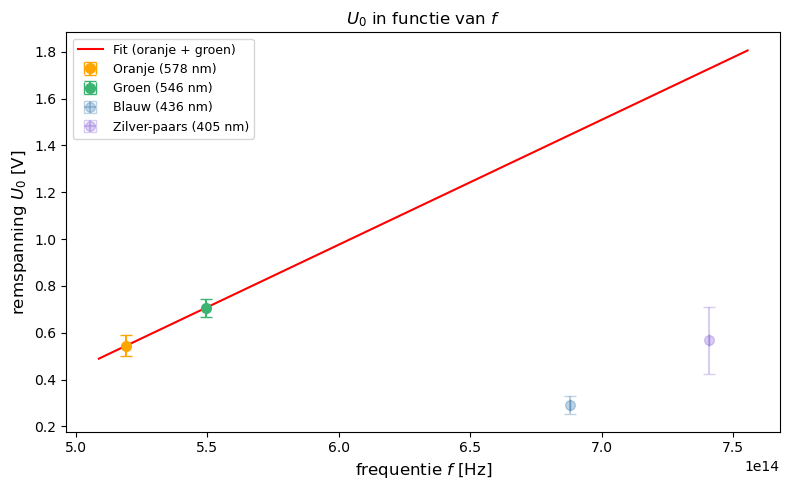

In [13]:
golflengtes_alle = np.array([578e-9, 546e-9, 436e-9, 405e-9])
c = 3e8
frequenties_alle = c / golflengtes_alle
fout_frequentie_alle = np.ones(4)

# Alleen oranje (578 nm) en groen (546 nm) voor de fit
idx_fit = [0, 1]
f1, f2   = frequenties_alle[idx_fit]
U1, U2   = np.array(Lijst_U0_1)[idx_fit]
sU1, sU2 = np.array(Lijst_fout_UO_1)[idx_fit]

# Analytische berekening helling en snijpunt voor 2 punten
# a = (U2 - U1) / (f2 - f1)
# b = U1 - a * f1
a_h = (U2 - U1) / (f2 - f1)
b_h = U1 - a_h * f1

# Foutpropagatie
# σ_a = sqrt(σ_U1² + σ_U2²) / |f2 - f1|
# σ_b = sqrt(σ_U1²*(1 + (f1/(f2-f1))²) + σ_U2²*(f1/(f2-f1))²)
df = f2 - f1
sa_h = np.sqrt(sU1**2 + sU2**2) / abs(df)
sb_h = np.sqrt(sU1**2 * (1 + (f1/df)**2) + sU2**2 * (f1/df)**2)

# Plot
fig3, ax3 = plt.subplots(figsize=(8, 5))
labels_alle = ["Oranje (578 nm)", "Groen (546 nm)", "Blauw (436 nm)", "Zilver-paars (405 nm)"]
kleuren_alle = ["orange", "mediumseagreen", "steelblue", "mediumpurple"]
for i in range(4):
    alpha = 1.0 if i in idx_fit else 0.35
    ax3.errorbar(frequenties_alle[i], Lijst_U0_1[i],
                 xerr=fout_frequentie_alle[i], yerr=Lijst_fout_UO_1[i],
                 fmt='o', color=kleuren_alle[i], markersize=7, capsize=4,
                 label=labels_alle[i], alpha=alpha)

f_lijn = np.linspace(min(frequenties_alle) * 0.98, max(frequenties_alle) * 1.02, 200)
ax3.plot(f_lijn, a_h * f_lijn + b_h, color='red', label='Fit (oranje + groen)')
ax3.set_xlabel("frequentie $f$ [Hz]", fontsize=12)
ax3.set_ylabel("remspanning $U_0$ [V]", fontsize=12)
ax3.set_title("$U_0$ in functie van $f$", fontsize=12)
ax3.legend(fontsize=9)
fig3.tight_layout()

e = 1.6e-19
h    = a_h * e
sh   = sa_h * e
W_A  = -b_h * e
sW_A = sb_h * e

print(f"h   = ({h:.3e} ± {sh:.3e}) J·s")
print(f"W_A = ({W_A:.3e} ± {sW_A:.3e}) J  =  ({W_A/e:.3f} ± {sW_A/e:.3f}) eV")


In [14]:
datasets_1B = [
    (V_O,  I_O,  dV_O,  dI_O,  "l = 0 cm",  "tab:blue"),
    (V_O3, I_O3, dV_O3, dI_O3, "l = 3 cm",  "tab:orange"),
    (V_O6, I_O6, dV_O6, dI_O6, "l = 6 cm",  "tab:green"),
    (V_O9, I_O9, dV_O9, dI_O9, "l = 9 cm",  "tab:red"),
]

Proef 1B – remspanning U₀ (oranje filter)
-----------------------------------
  l = 0 cm      U₀ = (0.545 ± 0.045) V
  l = 3 cm      U₀ = (0.777 ± 0.064) V
  l = 6 cm      U₀ = (0.642 ± 0.078) V
  l = 9 cm      U₀ = (0.699 ± 0.106) V


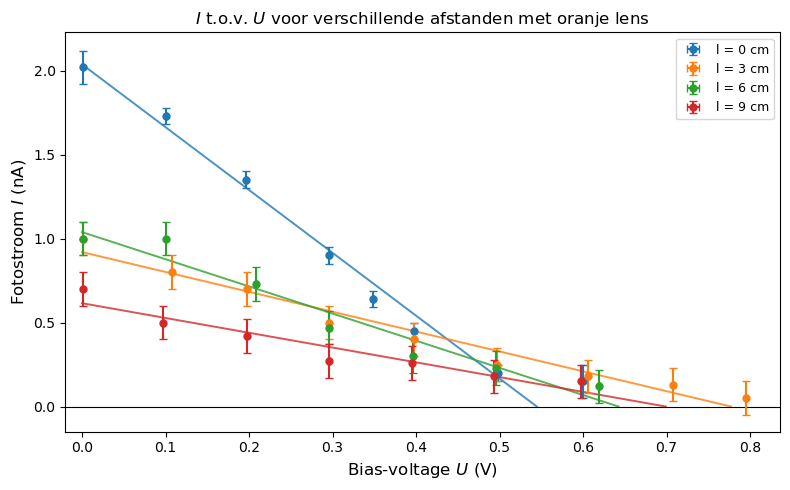

In [15]:
Lijst_U0_1 =[]
Lijst_fout_UO_1=[]


fig2, ax2 = plt.subplots(figsize=(8, 5))
 
print("Proef 1B – remspanning U₀ (oranje filter)")
print("-" * 35)
 
for V, I, dV, dI, label, color in datasets_1B:
    V, I, dV, dI = np.array(V), np.array(I), np.array(dV), np.array(dI)
    ax2.errorbar(V, I, xerr=dV, yerr=dI,
                 fmt='o', color=color, markersize=5, capsize=3,
                 label=label, zorder=3)
    
    a, b, U0, sU0 = find_U0(V, I, dI)
    Lijst_U0_1.append(U0)
    Lijst_fout_UO_1.append(sU0)
 
    if not np.isnan(U0):
        V_fit = np.linspace(0, U0, 100)
        ax2.plot(V_fit, a * V_fit + b, color=color, linewidth=1.4,
                 linestyle='-', alpha=0.8)
        print(f"  {label:<12s}  U₀ = ({U0:.3f} ± {sU0:.3f}) V")
    
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_xlabel("Bias-voltage $U$ (V)", fontsize=12)
ax2.set_ylabel("Fotostroom $I$ (nA)", fontsize=12)
ax2.set_title("$I$ t.o.v. $U$ voor verschillende afstanden met oranje lens", fontsize=12)
ax2.legend(fontsize=9)
ax2.set_xlim(left=-0.02)
ax2.set_ylim(bottom=-0.15)
fig2.tight_layout()

<ErrorbarContainer object of 3 artists>

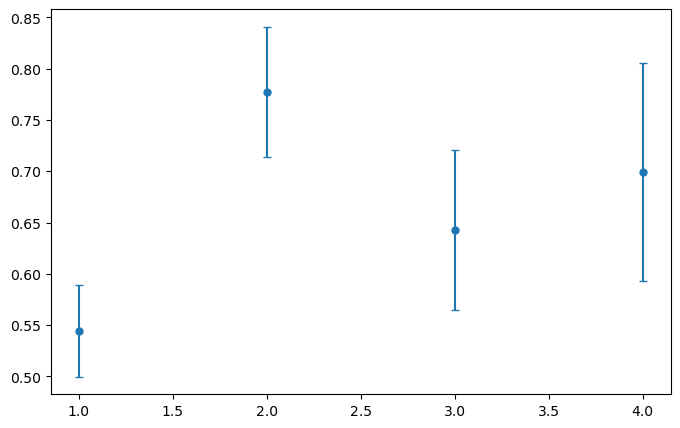

In [16]:
fig4, ax4 = plt.subplots(figsize=(8, 5))
t = [1,2,3,4]
ax4.errorbar(t,Lijst_U0_1,yerr= Lijst_fout_UO_1,fmt='o', markersize=5, capsize=3)